# 01 · Supply audit — where London's chargers are, and where EV owners are

**Question.** How does London's public charging supply (31k chargers, only 8 % rapid) relate to where plug-in cars are kept and to housing that lacks off-street parking?

**Data (all observed).** DfT EVCI statistics 1 July 2026 (borough totals, 50 kW+), OpenStreetMap 2026 charging stations (hub-biased sample), National Chargepoint Registry snapshot May 2021 (complete for its date), Census 2021, DfT vehicle licensing 2026 Q1 by LSOA, all moved to H3 resolution 8.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


## 1. Official borough picture (DfT, 1 July 2026)

London total chargers: 31371  rapid (50kW+): 2533  rapid share 8.1%


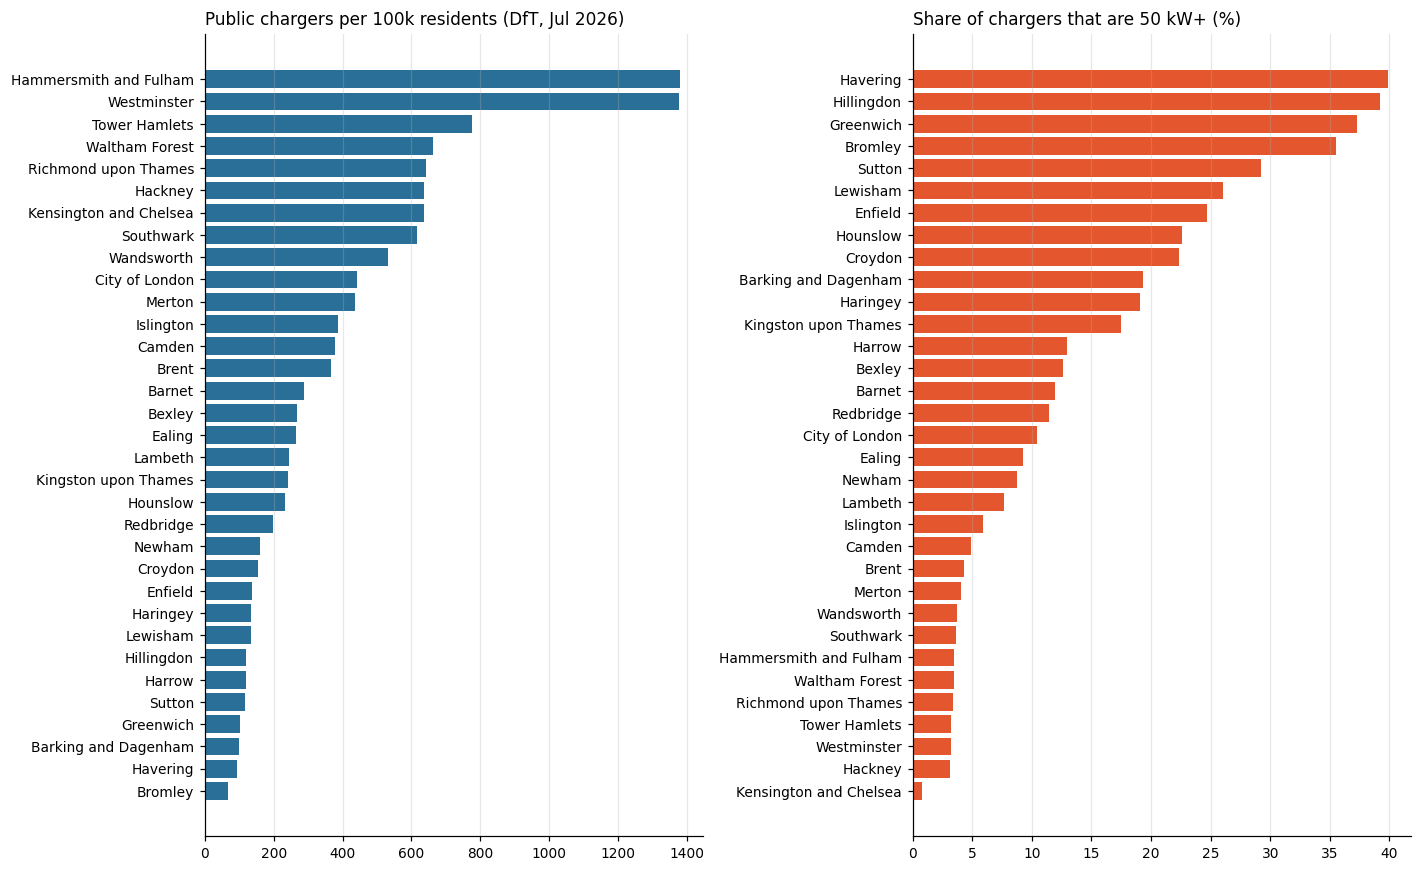

measure,rapid,rapid_per_100k,50kW+ EV charging devices (historic quarterly series; 25kW+ before Oct-23),50kW+ EV charging devices per 100k population (historic quarterly series; 25kW+ before Oct-23),chargers,chargers_per_100k,EV charging devices (historic quarterly series),EV charging devices per 100k population (historic quarterly series),rapid_share
area_name,,,,,,,,,
Hammersmith and Fulham,90.0,47.70,67.0,35.51,2603.0,1379.53,2506.0,1328.13,0.03
Westminster,92.0,43.81,68.0,32.38,2893.0,1377.65,2827.0,1346.22,0.03
Tower Hamlets,82.0,24.71,50.0,15.07,2574.0,775.57,2526.0,761.10,0.03
Waltham Forest,64.0,22.88,46.0,16.44,1855.0,663.12,1607.0,574.47,0.03
Richmond upon Thames,43.0,21.86,31.0,15.76,1263.0,642.17,1239.0,629.96,0.03
Hackney,53.0,19.87,29.0,10.87,1701.0,637.66,1671.0,626.41,0.03
Kensington and Chelsea,7.0,4.84,4.0,2.77,921.0,637.29,910.0,629.68,0.01
Southwark,70.0,22.24,44.0,13.98,1945.0,617.88,1888.0,599.77,0.04
Wandsworth,67.0,19.84,47.0,13.92,1795.0,531.61,1696.0,502.29,0.04


In [2]:
dft = pd.read_parquet(INTERIM / "chargepoints" / "dft_evci_london_la.parquet")
la = dft[(dft.geography == "local_authority") & (dft.date == dft.date.max())]
tab = la.pivot_table(index="area_name", columns="measure", values="value").rename(columns={"EV chargers": "chargers", "50kW+ EV chargers": "rapid", "EV chargers per 100k": "chargers_per_100k", "50kW+ EV chargers per 100k": "rapid_per_100k"})
tab["rapid_share"] = tab["rapid"] / tab["chargers"]
print("London total chargers:", int(tab.chargers.sum()), " rapid (50kW+):", int(tab.rapid.sum()), f" rapid share {tab.rapid.sum()/tab.chargers.sum():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
barh(tab["chargers_per_100k"], "Public chargers per 100k residents (DfT, Jul 2026)", ax=axes[0])
barh(tab["rapid_share"] * 100, "Share of chargers that are 50 kW+ (%)", ax=axes[1], color="#e4572e")
plt.tight_layout(); save(fig, "01_borough_supply.png"); plt.show()
tab.sort_values("chargers_per_100k", ascending=False).round(2).head(10)

**Reading.** Inner boroughs (Hammersmith & Fulham, Westminster) have ~1,400 chargers per 100k residents, mostly lamp-post 5–7 kW units; rapid share is highest in outer boroughs (Havering, Hillingdon ~40 %) and below 4 % in Westminster, Hackney and Kensington & Chelsea. Density of *devices* and density of *power* are different maps.

## 2. Hex view: chargers, private EVs and housing form

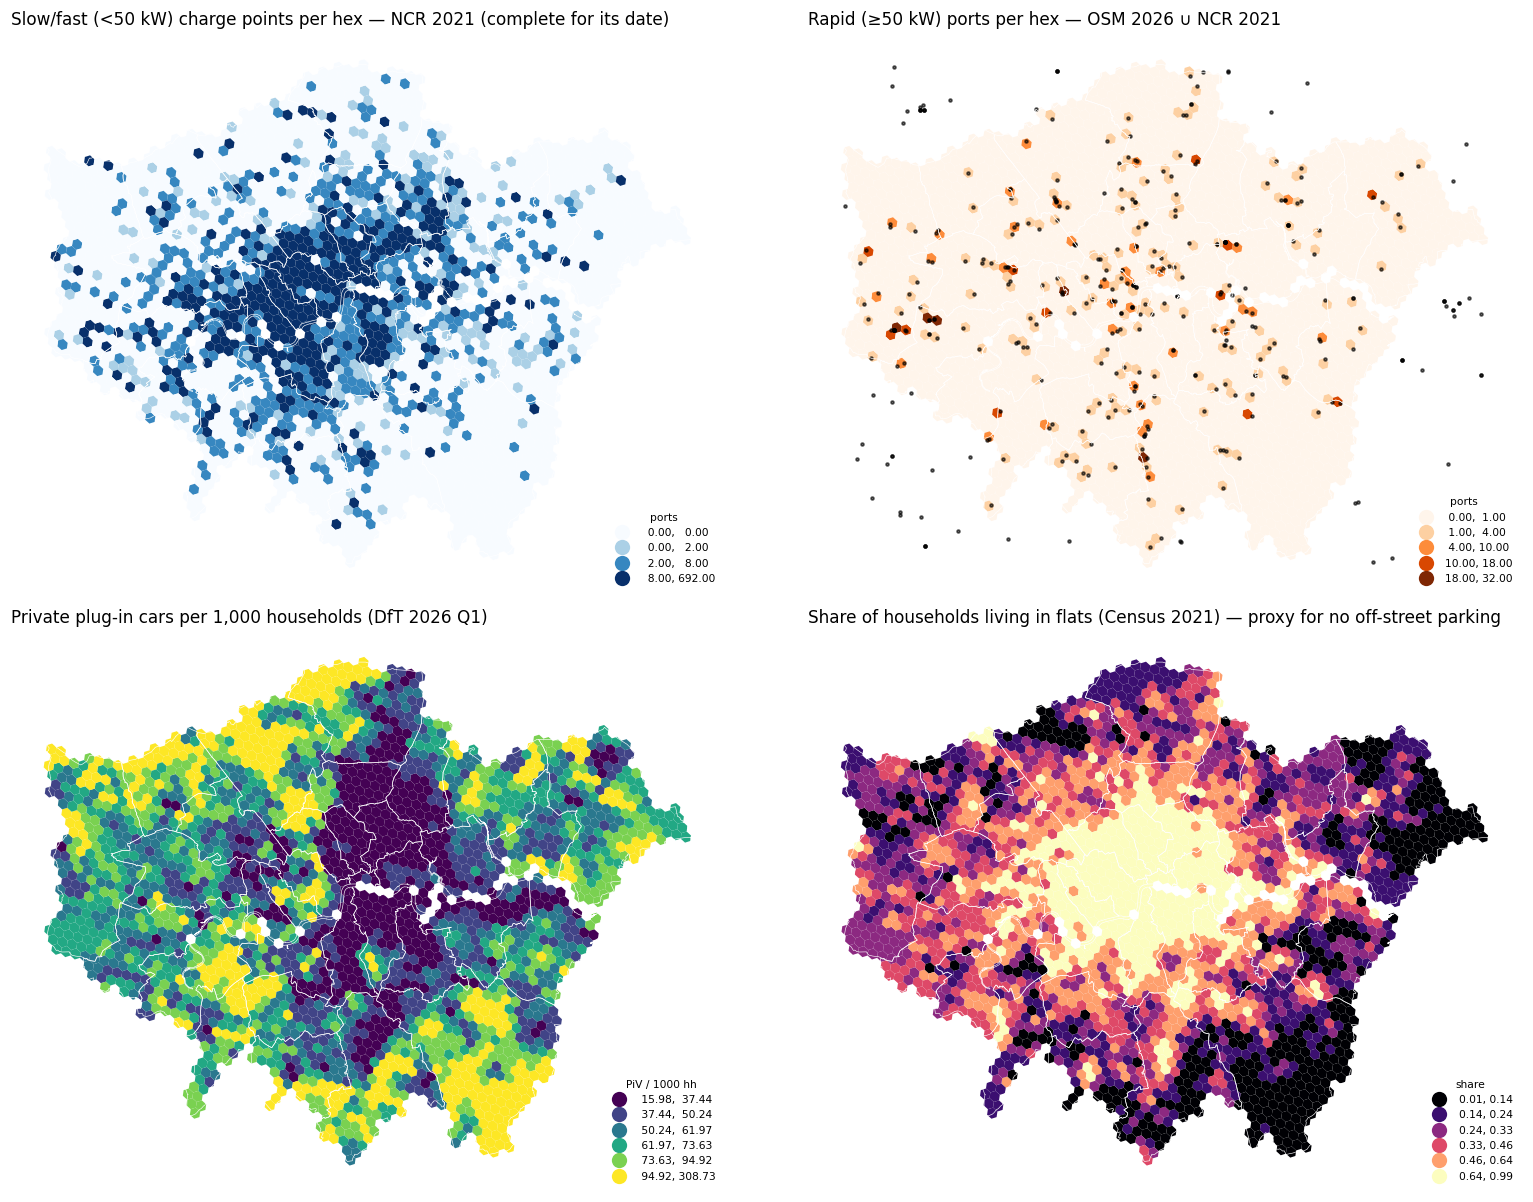

In [3]:
sites = read_gdf(PROCESSED / "charging_sites.parquet")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
hex_map(feats, "ports_slow", "Slow/fast (<50 kW) charge points per hex — NCR 2021 (complete for its date)", cmap="Blues", scheme="quantiles", k=6, ax=axes[0, 0], legend_label="ports")
hex_map(feats, "ports_rapid", "Rapid (≥50 kW) ports per hex — OSM 2026 ∪ NCR 2021", cmap="Oranges", scheme="fisher_jenks", k=5, ax=axes[0, 1], legend_label="ports", points=sites[sites.is_rapid], point_kw={"markersize": 4, "color": "black", "alpha": 0.6})
hex_map(feats, "piv_private_per_1000_hh", "Private plug-in cars per 1,000 households (DfT 2026 Q1)", cmap="viridis", scheme="quantiles", k=6, ax=axes[1, 0], legend_label="PiV / 1000 hh")
hex_map(feats, "share_flat", "Share of households living in flats (Census 2021) — proxy for no off-street parking", cmap="magma", scheme="quantiles", k=6, ax=axes[1, 1], legend_label="share")
plt.tight_layout(); save(fig, "01_hex_supply_demand.png"); plt.show()

## 3. Is the pattern clustered? Global and local spatial autocorrelation

               variable  Moran_I  p_sim
piv_private_per_1000_hh    0.731  0.002
             share_flat    0.822  0.002
             ports_slow    0.154  0.002
            ports_rapid    0.074  0.002
              vkm_total    0.345  0.002


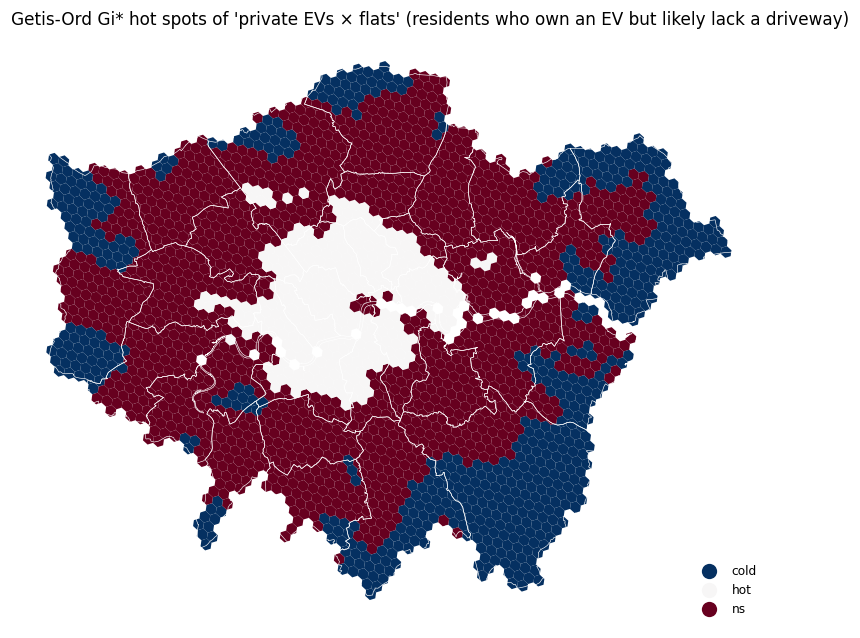

In [4]:
from chargescape.features.spatial_stats import h3_weights, morans_i, local_hotspots
w = h3_weights(feats["h3"])
rows = []
for col in ["piv_private_per_1000_hh", "share_flat", "ports_slow", "ports_rapid", "vkm_total"]:
    m = morans_i(feats[col].fillna(0), w, permutations=499)
    rows.append({"variable": col, "Moran_I": m["I"], "p_sim": m["p_sim"]})
moran = pd.DataFrame(rows).round(3); print(moran.to_string(index=False))
feats["need_index"] = feats["piv_private_est"].fillna(0) * feats["share_flat"].fillna(0)
hs = local_hotspots(feats["need_index"], w, permutations=499)
feats["need_hotspot"] = hs["hotspot"].values
fig, ax = plt.subplots(figsize=(9, 7))
feats.to_crs(27700).plot(column="need_hotspot", categorical=True, cmap="RdBu_r", ax=ax, legend=True, linewidth=0, legend_kwds={"loc": "lower right", "fontsize": 8, "frameon": False})
boroughs().boundary.plot(ax=ax, color="white", linewidth=0.4); ax.set_axis_off()
ax.set_title("Getis-Ord Gi* hot spots of 'private EVs × flats' (residents who own an EV but likely lack a driveway)", loc="left")
save(fig, "01_need_hotspots.png"); plt.show()

## 4. Gap analysis: high need, far from rapid charging (network drive time)

hexes in top-quartile need with no rapid site within 6 min drive: 8 (1,099 private EVs)


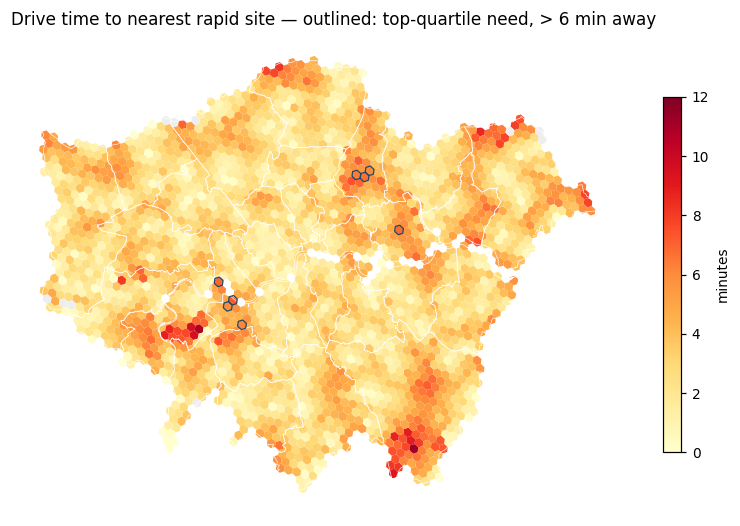

,hexes,private_evs,mean_tt
borough,,,
Wandsworth,3,491.8,6.5
Waltham Forest,3,309.7,6.4
Newham,1,165.1,6.8
Richmond upon Thames,1,132.8,6.9


In [5]:
svc = pd.read_parquet(PROCESSED / "hex_service_2026.small.parquet").set_index("h3")
feats["tt_nearest_rapid_min"] = feats["h3"].map(svc["tt_nearest_rapid_min"])
gap = feats[(feats["need_index"] > feats["need_index"].quantile(0.75)) & (feats["tt_nearest_rapid_min"] > 6)]
print(f"hexes in top-quartile need with no rapid site within 6 min drive: {len(gap)} ({gap['piv_private_est'].sum():,.0f} private EVs)")
fig, ax = plt.subplots(figsize=(9, 7))
hex_map(feats, "tt_nearest_rapid_min", "Drive time to nearest rapid site (min, OSM network + igraph)", cmap="YlOrRd", vmin=0, vmax=12, ax=ax, legend_label="minutes")
gap.to_crs(27700).boundary.plot(ax=ax, color="#1b4965", linewidth=0.8)
ax.set_title("Drive time to nearest rapid site — outlined: top-quartile need, > 6 min away", loc="left")
save(fig, "01_gap_rapid_access.png"); plt.show()
gap.groupby("borough").agg(hexes=("h3", "size"), private_evs=("piv_private_est", "sum"), mean_tt=("tt_nearest_rapid_min", "mean")).sort_values("private_evs", ascending=False).round(1).head(12)

## Takeaways
* Supply follows *devices*, need follows *cars without driveways*: the densest slow networks sit in inner boroughs, the largest private EV stocks in outer, house-rich boroughs — but the group that depends most on public charging (EV owners in flats) forms distinct hot spots, mostly in inner-west and inner-south London.
* Rapid access is uneven: several high-need clusters are more than six minutes' drive from any rapid site on the road network.
* Everything above is observed data; the next notebook turns it into a demand surface with explicit uncertainty.